# Zonal Statistics

*Section 3 — Vector data and zonal statistics, notebook 1 of 2.* Previous: `02_making_maps/04_combining_data_sources.ipynb`. Next: `02_semivariograms.ipynb`.

**You will learn:**
- how to extract raster values to points (`rsgispy.zonalstats.point.ext_point_band_values`);
- how to buffer points into polygons and calculate zonal statistics within them (`rsgispy.zonalstats.polygon`);
- how to calculate statistics for every band of an image stack for a set of field polygons;
- how to explore and model the extracted time-series signal with NumPy and SciPy.

**Before you start:** image metadata from `01_getting_started` and the image/vector maps from `02_making_maps`.

**Data:** `../data/Sentinel1_MonthlyMean_2018_lin_100000_Geog_subset.tif` (monthly Sentinel-1 means, Mekong Delta), `../data/sample_locations_utm.gpkg` (sample points) and `../data/tile_segs_mskd_lbl_vec111.gpkg.zip` (field boundaries, read from inside the zip file).

**Run time:** less than 1 minute.

In this tutorial we will look at populating various vector formats (points and polygons) from raster images for looking at fallow, growing and cropping cycles in agricultural/rice paddies in Vietnam, using radar imagery. Radar data is measured in backscatter where high values are associated with high structure (vegetation) and low values are associated with low structure (non_vegetated/water/bare).

You will learn the following:

- Extract raster values to point for specifc locations
- Extract raster statistics to buffered points (polygons)
- Extract raster stack statistics for agricultural fields (image objects)
- Explore extracted time-series signal

In rsgispy the vector layers are held in memory as [GeoPandas](https://geopandas.org) `GeoDataFrame`s: the zonal statistics functions take a `GeoDataFrame` (or a file path), add the new columns and return the `GeoDataFrame`, which you can then save with `to_file`.

**RSGISLib users:** the OGR in-memory layers (`read_vec_lyr_to_mem` / `write_vec_lyr_to_file`) are replaced by GeoPandas `GeoDataFrame`s. The `*_file` versions of the functions (e.g., `ext_point_band_values_file`) read a file and write the result to the same or a new file in one step.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook and be browsed online without having to run the notebook for it to make sense. 

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_



# 1. Importing Modules

The first step is to import the modules for the analysis we are to undertake:

In [1]:
import os

# Import Geopandas for vector analysis (https://geopandas.org)
import geopandas

# Additional modules for visualization
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

# Import Numpy array module
import numpy

# Import rsgispy modules
import rsgispy
import rsgispy.imageutils.metadata
import rsgispy.mapping.raster
import rsgispy.vector.io

# Note, you can import a list of modules rather than
# listing each individually.
from rsgispy.zonalstats import point, polygon

# All the outputs from this notebook are written to the outputs directory
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# 2. Data

Firstly, lets look at our imagery. Here you will find a stack of Sentinel-1 radar imagery captured over a small region of the Mekong Delta in Vietnam. Each band of the image is a monthly average over the course of a year, from January through December. The image is is linear radar units (power) but is scaled by 10,000. We can look at some basic image metadata and parameters using:

In [2]:
input_img = "../data/Sentinel1_MonthlyMean_2018_lin_100000_Geog_subset.tif"

In [3]:
# Call function to get the input image size:
x_size, y_size = rsgispy.imageutils.metadata.get_img_size(input_img)
print(f"Image dimensions: {x_size} x {y_size}")

# Call function to get the input image number of bands:
n_bands = rsgispy.imageutils.metadata.get_img_band_count(input_img)
print(f"Number of Bands: {n_bands}")

# Call function to get the input image band names:
band_names = rsgispy.imageutils.metadata.get_band_names(input_img)
print(f"Band Names: {band_names}")

# Call function to get the input image resolution:
x_res, y_res = rsgispy.imageutils.metadata.get_img_res(input_img)
print(f"Image Resolution: ({round(x_res, 2)}, {round(y_res,2)}) m")

Image dimensions: 1370 x 1180
Number of Bands: 12
Band Names: ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Image Resolution: (10.0, -10.0) m


A point GeoPackage has been provided for you, which we will use to extract pixel values.

In [4]:
points_vec_file = "../data/sample_locations_utm.gpkg"

The first step is to check the number of field points that we have

In [5]:
feat_num = rsgispy.vector.io.get_vec_feat_count(points_vec_file)
print(f"number of points: {feat_num}")

number of points: 24


Let us also use the rsgispy mapping tools to visualize the radar image with the points overlain. Try changing the band combination `img_bands=[1,2,3]` to visualise the different bands. Try `img_bands=[1]`, `img_bands=[2]`, `img_bands=[3]` and `img_bands=[6,7,8]`, for example.

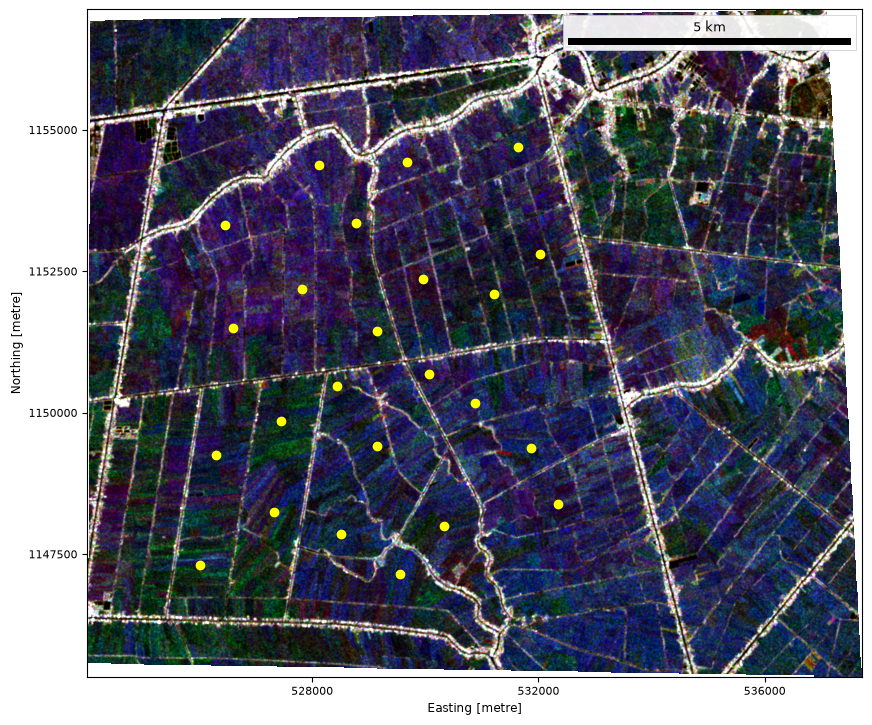

In [6]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
# Add the stretched image data to the plot and define the spatial
# extent so the axis labels are the coordinates.
_ = rsgispy.mapping.raster.create_raster_img_map(ax, input_img, img_bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE)

# Read points to geopandas dataframe
points_gdf = geopandas.read_file(points_vec_file)
# Plot the plots over the image data
_ = points_gdf.plot(ax=ax, color="yellow")

# 3. Extract values to point

Firsty, let us consider the scenario whereby image values are needed at field plot locations. For a band of interest we can extract the pixel values at these point locations.

We will start by reading the vector points into memory as a GeoPandas `GeoDataFrame`, using:

In [7]:
# Get list of layer names in vector file
vec_lyrs = rsgispy.vector.io.get_vec_lyrs_lst(points_vec_file)
print(f"list of vector layers: {vec_lyrs}")

# Get first name from vec_lyrs list
lyr_name = vec_lyrs[0]

# Read vector layer to memory
points_gdf = geopandas.read_file(points_vec_file, layer=lyr_name)

list of vector layers: ['sample_locations_utm']


This creates a `GeoDataFrame` (`points_gdf`) which stores the vector in memory. Next we will define the input parameters for the extract to point command.

In [8]:
# The image band in the raster stack
img_band = 2
# The minimum value that the point will extract
min_thres = 1
# The maximum value that the point will extract
max_thres = 10000
# The no data value which will not be extracted, but will be used in the case where there is no valid pixel value
out_no_data_val = 0
# The name of the output field in the att table (note, field names are written in lower case)
out_field = "February"
# whether to reproject the vector on-the-fly to match the image
reproj_vec = False
# Specify the epsg for the vector if the WKT is not well defined
vec_def_epsg = None

points_gdf = rsgispy.zonalstats.point.ext_point_band_values(
    points_gdf,
    input_img,
    img_band,
    min_thres,
    max_thres,
    out_no_data_val,
    out_field,
    reproj_vec,
    vec_def_epsg,
)

  0%|          | 0/24 [00:00<?, ?it/s]

Now that we have extracted the pixel values, the final step is to write the vector layer to a new GeoPackage file.

In [9]:
# the output file to write the data to.
points_stats_vec_file = os.path.join(out_dir, "sample_locations_utm_stats.gpkg")

# Write the GeoDataFrame to a GeoPackage file (the layer name matches the input layer name)
points_gdf.to_file(points_stats_vec_file, layer=lyr_name, driver="GPKG")

While this shows how layers can be read into memory, populated and written back to a file (GeoPackage), this is mostly used when lots of image values are populated into dataset in one go. rsgispy also has a function to achieve our workflow in one step using the command: `rsgispy.zonalstats.point.ext_point_band_values_file`, which reads the input file and writes the output file (`out_vec_file`). Note, `ext_point_band_values` can also extract several bands at once if you give it a list of band numbers.

Now we have written the updated layer to the dataset, we can open the vector and look at the values we have extracted:

In [10]:
# Open the gpkg file with geopandas
gdf = geopandas.read_file(points_stats_vec_file)

# View the first 5 attributes
gdf.head()

,id,february,geometry
0,0,1181.0,POINT (526459.321 1153316.974)
1,1,1365.0,POINT (526604.807 1151498.406)
2,2,1527.0,POINT (527441.348 1149861.694)
3,3,601.0,POINT (529950.972 1152371.318)
4,4,1267.0,POINT (529678.187 1154426.301)


# 4. Extract image statistics within a polygon

Extracting values to a point location is useful, but it is not always known if the pixel value represents the point location accuratley. Often it is preferred that a number of pixels are sampled and represented by a single statistic (e.g., mean) which may be more representative and reduces error due to geolocation etc.

To do this, firstly we need to buffer our points to get polygons. We will buffer our points by 100 m.

The points vector is already open from the above step:

`gdf = geopandas.read_file(points_stats_vec_file)`

Therefore we can buffer the points with:

In [11]:
# Buffer the points geometry with 100 m
gdf["geometry"] = gdf.geometry.buffer(100)

# Buffered points output file name and path
buffered_points_vec_file = os.path.join(out_dir, "sample_locations_utm_buffer100.gpkg")

# Write the buffered points to a new file with points buffered by 100 m
gdf.to_file(buffered_points_vec_file, driver="GPKG")

We can visualize the buffered points (yellow) behind our original points on a figure using:

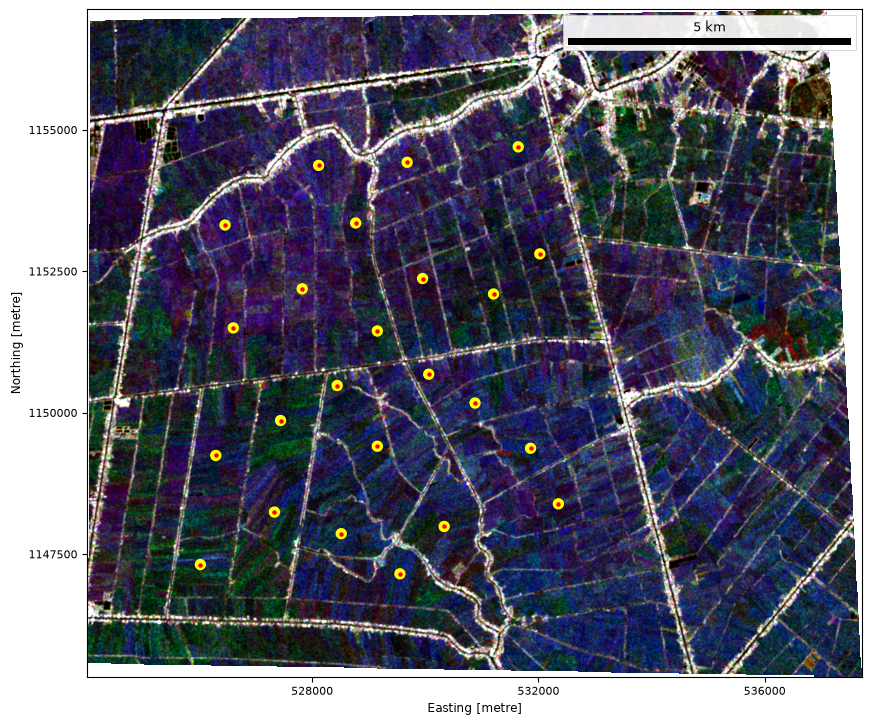

In [12]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
# Add the image to the axis
_ = rsgispy.mapping.raster.create_raster_img_map(ax, input_img, img_bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE)

# Read points to geopandas dataframe
buff_points_gdf = geopandas.read_file(buffered_points_vec_file)

# Plot the buffered plots and points over the image data
_ = buff_points_gdf.plot(ax=ax, color="yellow")
_ = points_gdf.plot(ax=ax, color="red", markersize=5)

Now that we have buffered points we can now use the functions within rsgispy to extract image statistics from image pixels that are overlapped by the polygons. Each pixel below the polygon will be included in the statistics, provided that the polygon intersects the pixel centroid (middle point).

We begin again by getting the vector layer name that we want to use:

In [13]:
# Get list of layer names in vector file
vec_lyrs = rsgispy.vector.io.get_vec_lyrs_lst(buffered_points_vec_file)
# Get first name from vec_lyrs list
lyr_name = vec_lyrs[0]
print(f"layer name: {lyr_name}")

layer name: sample_locations_utm_buffer100


As we know that the pixel size is smaller than our polygons, we can use the following command to get the min, max and mean pixel values. Here we will not read the layer into memory first as we extracting values from only one image band so we will use the `_file` version of the function, which reads the vector file and writes the result back to it (as `out_vec_file` is not given):

In [14]:
# vector file
vec_file = buffered_points_vec_file
# vector layer name
vec_lyr = lyr_name
# raster stack image band
img_band = 2
# The minimum value that the point will extract
min_thres = 1
# The maximum value that the point will extract
max_thres = 10000
# The no data value which will not be extracted, but will be used in the case where there is no valid pixel value
out_no_data_val = 0
# The name of the output fields to write to the att table
mean_field_name = "Feb_mean"
min_field_name = "Feb_min"
max_field_name = "Feb_max"
# Specify the epsg for the vector if the WKT is not well defined
vec_def_epsg = None

rsgispy.zonalstats.polygon.calc_zonal_band_stats_test_poly_pts_file(
    vec_file=vec_file,
    vec_lyr=vec_lyr,
    input_img=input_img,
    img_band=img_band,
    min_thres=min_thres,
    max_thres=max_thres,
    out_no_data_val=out_no_data_val,
    min_field=min_field_name,
    max_field=max_field_name,
    mean_field=mean_field_name,
    vec_def_epsg=vec_def_epsg,
)

  0%|          | 0/24 [00:00<?, ?it/s]

We can now look at these pixel stats in the attribute table of the vector

In [15]:
# Open the gpkg file with geopandas
gdf = geopandas.read_file(buffered_points_vec_file)

# View the first 5 attributes
gdf.head()

,id,february,feb_min,feb_max,feb_mean,geometry
0,0,1181.0,803.0,2083.0,1315.438710,"POLYGON ((526559.321 1153316.974, 526558.84 11..."
1,1,1365.0,903.0,2986.0,1618.439490,"POLYGON ((526704.807 1151498.406, 526704.325 1..."
2,2,1527.0,858.0,2538.0,1571.277070,"POLYGON ((527541.348 1149861.694, 527540.867 1..."
3,3,601.0,429.0,2484.0,1126.662420,"POLYGON ((530050.972 1152371.318, 530050.491 1..."
4,4,1267.0,906.0,2393.0,1500.083067,"POLYGON ((529778.187 1154426.301, 529777.706 1..."


Here we can see the column 'february' which was extracted to the points vector file and the three february statistics that were populated into the polygons (buffered points). Note, the output field names are written in lower case.

# 5. Time-series zonal stats analysis

We have seen how you can populate polygons with statistics from an image. Now we will look at an applied example, where we will look at time-series signals from agricultural fields to understand cropping cycles. We will look specifically at a region in the Mekong Delta of Vietnam and evaluate how many cropping cycles there are over the course of a year. This example is taken from work in:  https://doi.org/10.3390/rs12203459

You have been provided with a GeoPackage of field boundaries created from VHR Worldview imagery. We will begin by looking at this shapefile and the Sentinal-1 radar imagery that we have used so far in this tutorial.

---
In this case as the GPKG file with the field boundaries is quite large as an uncompressed file we will read it as a compressed dataset. Note, to do this we have to reference the file path slightly differently, specifying the path as a zip compressed file (using the GDAL `/vsizip/` prefix) and then the path within the zip file to the GPKG file we are wanting to open. GeoPandas reads the file through GDAL, so it understands these paths.

You cannot write to a zipped vector layer but if the layer is only going to be used for reading and not to be written to it can save a lot of disk space! In this case `tile_segs_mskd_lbl_vec111.gpkg.zip` is **87 %** smaller than `tile_segs_mskd_lbl_vec111.gpkg`.

---

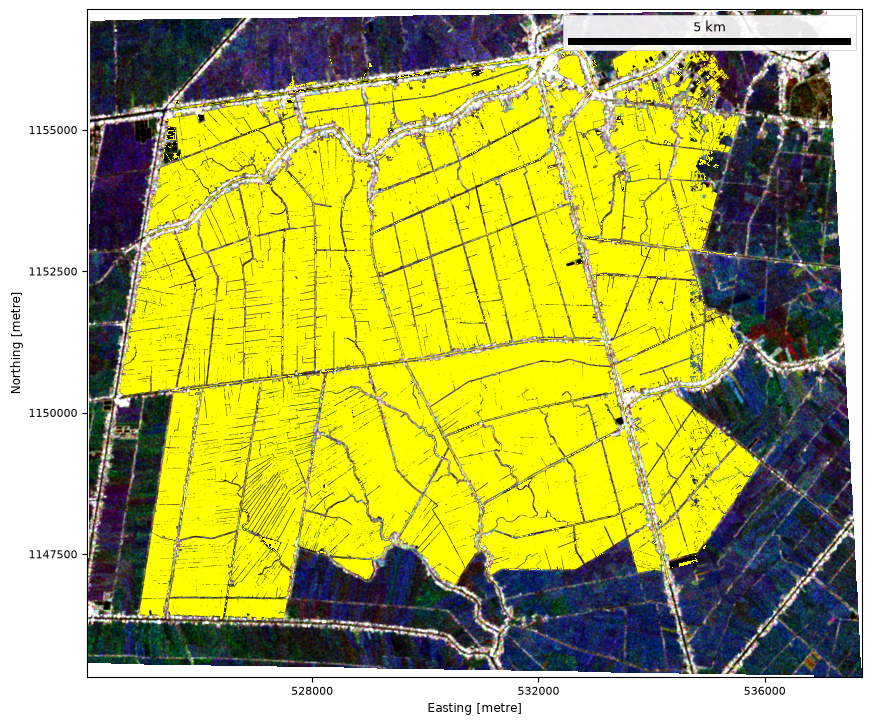

In [16]:
# Field polygons - Note. /vsizip/ specifies that we are openning a zip file.
# The path to the zip file is: ../data/tile_segs_mskd_lbl_vec111.gpkg.zip
# The path to the GPKG file we want to open within the zip file is:
# tile_segs_mskd_lbl_vec111.gpkg
in_field_vec = (
    "/vsizip/../data/tile_segs_mskd_lbl_vec111.gpkg.zip/tile_segs_mskd_lbl_vec111.gpkg"
)

# Read points to geopandas dataframe
field_polys = geopandas.read_file(in_field_vec)

# We already opened the image and calculated the image stretch parameters from
# stretch parameters from the first visualization

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
# Add the image to the axis
_ = rsgispy.mapping.raster.create_raster_img_map(ax, input_img, img_bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE)


# Plot the fields over the image data
_ = field_polys.plot(ax=ax, color="yellow")

Here we will replicate the zonal statistics like in section 4, but will iterate the command over each image band.

First we need the vector layer name. We can use `pyogrio` (the library GeoPandas uses to read vector files) to list the layers within the zipped GeoPackage:

In [17]:
import pyogrio

# Get list of layer names (and geometry types) in vector file
vec_lyrs = pyogrio.list_layers(in_field_vec)

# Get first name from vec_lyrs list
lyr_name = vec_lyrs[0][0]
print(f"layer name: {lyr_name}")

layer name: tile_segs_mskd_lbl_vec111


We will now need to create a list to iterate over each band of the image and assign a unique field name for each image band:

In [18]:
# Create an array of image band numbers using the module numpy
image_bands = numpy.arange(1, 13, 1)
print(f"image bands: {image_bands}")

# Create a list of attribute fields we will populate
out_fields_list = [
    "jan_mean",
    "feb_mean",
    "mar_mean",
    "apr_mean",
    "may_mean",
    "jun_mean",
    "jul_mean",
    "aug_mean",
    "sep_mean",
    "oct_mean",
    "nov_mean",
    "dec_mean",
]

image bands: [ 1  2  3  4  5  6  7  8  9 10 11 12]


As we are reading 12 bands into the layer, it would be inefficient to do this in the same manner as above as we will have to read, populate and write the vector each time. Instead, it is more efficient to read the layer into memory once, populate the values and write out the data once.

We will start by reading the layer into memory as a `GeoDataFrame`:

In [19]:
# Read vector layer to memory
fields_gdf = geopandas.read_file(in_field_vec, layer=lyr_name)

We can now iterate over these lists, running the command a total of 12 times:

In [20]:
# set up a for loop to iterate over the image bands list and execute the command
for band in image_bands:
    # specify the image band
    img_band_num = int(band)
    print(f"band number = {img_band_num}")
    # specify the out field (out fields list indexed to band, minus 1)
    mean_field_name = out_fields_list[band - 1]
    print(f"out field name = {mean_field_name}")
    # Run the command - the GeoDataFrame is updated with the new column
    fields_gdf = rsgispy.zonalstats.polygon.calc_zonal_band_stats_test_poly_pts(
        fields_gdf,
        input_img,
        img_band=img_band_num,
        min_thres=1,
        max_thres=10000,
        out_no_data_val=0,
        min_field=None,
        max_field=None,
        mean_field=mean_field_name,
        use_pbar=False,
    )

band number = 1
out field name = jan_mean


band number = 2
out field name = feb_mean


band number = 3
out field name = mar_mean


band number = 4
out field name = apr_mean


band number = 5
out field name = may_mean


band number = 6
out field name = jun_mean


... (2 outputs left out)

band number = 9
out field name = sep_mean


band number = 10
out field name = oct_mean


band number = 11
out field name = nov_mean


band number = 12
out field name = dec_mean


These values are held in the `GeoDataFrame` so should be written to a new file to save them (we cannot write into the zip file, and do not want to overwrite the original file anyway):

In [21]:
# output vector file path - changed to not overwrite the input file
field_stats_vec = os.path.join(out_dir, "tile_segs_mskd_lbl_vec111_stats.gpkg")

fields_gdf.to_file(field_stats_vec, layer=lyr_name, driver="GPKG")

Now we can look at the attribute table that we have populated:

In [22]:
# Open the gpkg file with geopandas
gdf = geopandas.read_file(field_stats_vec)

# View the first 5 attributes
gdf.head()

,PXLVAL,jan_mean,feb_mean,mar_mean,apr_mean,may_mean,jun_mean,jul_mean,aug_mean,sep_mean,oct_mean,nov_mean,dec_mean,geometry
0,5,3172.352941,2479.117647,3094.176471,4351.117647,3726.588235,4496.176471,4792.176471,3693.176471,2411.647059,2672.058824,3844.470588,3897.764706,"POLYGON ((532134.492 1156436.492, 532134.492 1..."
1,6,2486.085714,2324.857143,3156.200000,3128.600000,3476.657143,4412.142857,5168.257143,4882.885714,6055.914286,5711.200000,5702.228571,5334.742857,"POLYGON ((532505.492 1156397.492, 532505.492 1..."
2,8,4942.500000,3802.833333,4111.916667,3104.416667,4027.083333,3893.000000,3644.333333,3000.083333,3041.833333,3801.750000,4343.166667,3878.083333,"POLYGON ((531670.492 1156360.492, 531670.492 1..."
3,7,1890.520000,1581.840000,1601.240000,1685.840000,1877.640000,2167.840000,1929.240000,1922.880000,1925.080000,1929.640000,1933.480000,1857.880000,"POLYGON ((532460.492 1156367.492, 532460.492 1..."
4,12,4650.000000,4420.437500,3629.875000,4023.812500,4434.437500,3888.062500,3813.875000,3983.500000,3958.687500,4495.250000,4400.125000,3953.625000,"POLYGON ((526327.492 1156328.492, 526327.492 1..."


### Time-series analysis

For this we will look at one specific field, by selecting a specific row (field) from the geopandas dataframe. Here we will use a combination of geopandas, numpy and matplotlib (within geopandas) to show how rsgispy can be combined with other python modules for you to  complete your analysis

In [23]:
# read row (field) number 207 and remove the PXLVAL (segment id) and geometry columns which are not needed
field = gdf.iloc[207].drop(["PXLVAL", "geometry"])
print(field)

jan_mean     1621.33506
feb_mean    1627.199291
mar_mean    2770.824427
apr_mean    2423.172846
may_mean    1635.747001
jun_mean    1573.271265
jul_mean    3109.101145
aug_mean    2913.543893
sep_mean    1323.565431
oct_mean    1956.055616
nov_mean    2615.757088
dec_mean    2262.254089
Name: 207, dtype: object


Which is visualized here:

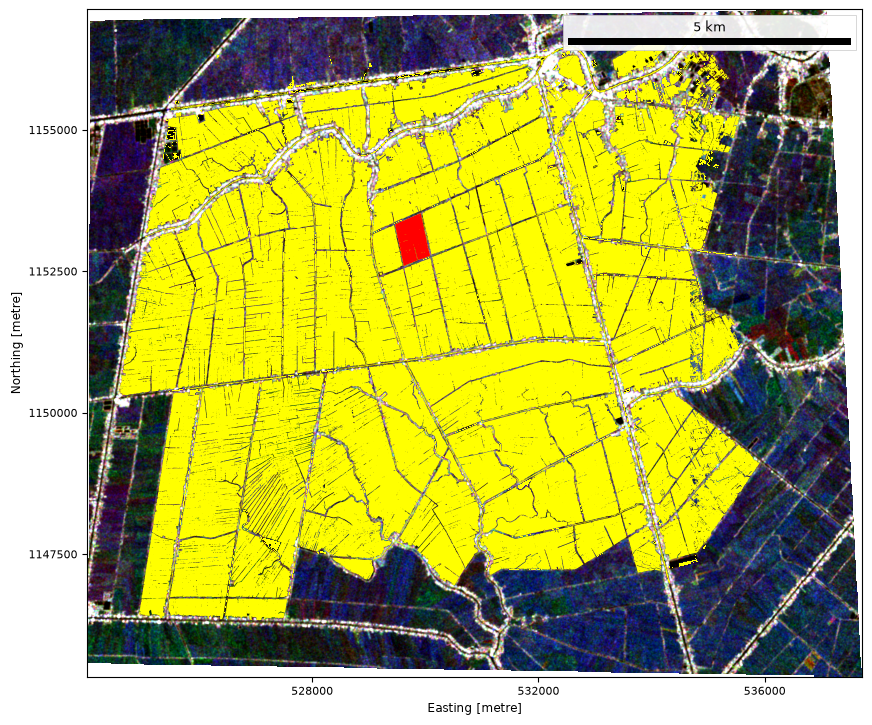

In [24]:
# The fields vector file was read in above to look at the attribute table

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
# Add the image to the axis
_ = rsgispy.mapping.raster.create_raster_img_map(ax, input_img, img_bands=[1, 2, 3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE)

# Plot the fields over the image data
_ = field_polys.plot(ax=ax, color="yellow")
# plot the field location geometry
_ = gdf.loc[[207], "geometry"].plot(ax=ax, color="red")

Make a list of the 12 months of data from the dataframe

In [25]:
# Convert the row to a numpy array of floats (the PXLVAL and geometry columns have been dropped)
field_vals = field.to_numpy().astype(float)
field_vals

array([1621.33505998, 1627.19929117, 2770.82442748, 2423.17284624,
       1635.74700109, 1573.27126499, 3109.10114504, 2913.54389313,
       1323.56543075, 1956.05561614, 2615.75708833, 2262.25408942])

The values we currently have are in linear power and multiplied by a scale factor of 10000. We should convert these values to decibel for plotting and visualization.

Firstly we will remove the scale factor:

In [26]:
# divide by 10000
field_vals_pwr = field_vals / 10000
field_vals_pwr

array([0.16213351, 0.16271993, 0.27708244, 0.24231728, 0.1635747 ,
       0.15732713, 0.31091011, 0.29135439, 0.13235654, 0.19560556,
       0.26157571, 0.22622541])

We can now convert these values to decibels (dB) using the standard formula for backscatter in power units:

$\sigma^0_{dB} = 10 \log_{10}(\sigma^0)$

Note, the original version of this tutorial used `10*log(x^2)` (with the natural logarithm), which gives values with the same shape but on a different scale; the formula above is the standard conversion for power (if the image were in amplitude units it would be $10 \log_{10}(x^2) = 20 \log_{10}(x)$).

In [27]:
field_vals_dB = 10 * numpy.log10(field_vals_pwr)
field_vals_dB

array([-7.90127226, -7.88559254, -5.57390992, -6.15615606, -7.86283867,
       -8.03196389, -5.07365149, -5.35578435, -8.78254584, -7.08618801,
       -5.82402589, -6.45458618])

We can plot this data like this:

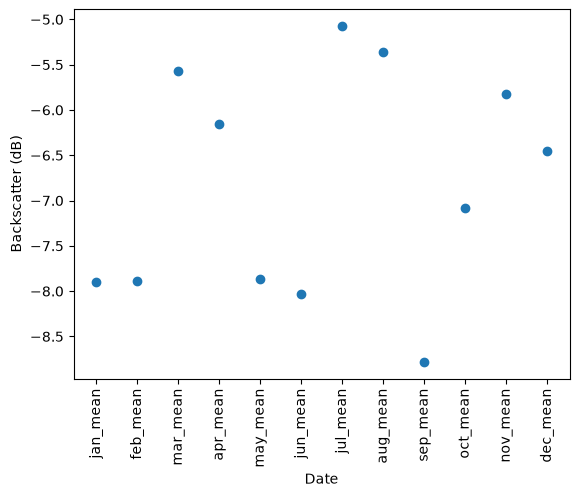

In [28]:
plt.scatter(out_fields_list, field_vals_dB)
plt.xlabel("Date")
plt.ylabel("Backscatter (dB)")
plt.xticks(rotation=90)
plt.show()

Finally, we can use the scipy module to fit a curve to our data points so we can better visualize the trend:

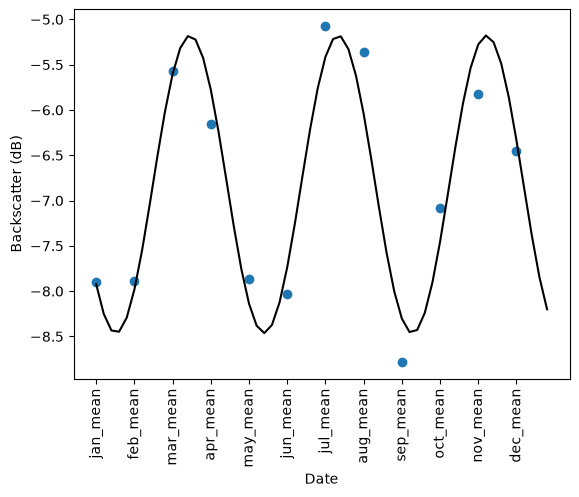

In [29]:
from scipy.optimize import curve_fit


# Fourier Series 1 Term (scaled X) from zunzun.com
def func(x, offset, a1, b1, c1):
    return a1 * numpy.sin(c1 * x) + b1 * numpy.cos(c1 * x) + offset


# these are the same as the scipy defaults
init_parameters = numpy.array([1.0, 1.0, 1.0, 1.0])

x_axis = numpy.arange(1, 13, 1)
x_model = numpy.arange(1, 13, 0.2)

fitted_parameters, pcov = curve_fit(func, x_axis, field_vals_dB, init_parameters)

model_predictions = func(x_model, *fitted_parameters)
mdl_pred = func(x_axis, *fitted_parameters)

# Plot the observations and model against the month number (1-12)
# and label the x axis with the field names.
plt.scatter(x_axis, field_vals_dB)
plt.plot(x_model, model_predictions, c="black")
plt.xlabel("Date")
plt.ylabel("Backscatter (dB)")
plt.xticks(x_axis, out_fields_list, rotation=90)
plt.show()

Here we can see that there are three distinct peaks associated with cropping cyles. The Mekong Delta is one of the only places on Earth where three rice cropping cycles are possible.